In [1]:
import xspec
import numpy as np
import os
import subprocess
import matplotlib.pyplot as plt
import re
import pandas as pd
from astropy.io import fits

In [2]:
os.chdir('/work2/sruedavargas/SAS-software/products/spectra_files')

In [3]:
xchat = xspec.Xset.chatter, xspec.Xset.logChatter
xspec.Xset.chatter    = 0
xspec.Xset.logChatter = 0

In [4]:
# xspec.Xset.chatter, xspec.Xset.logChatter = xchat

In [5]:
xspec.AllData.clear()

In [6]:
mos1_12_data = 'av_spec_0554170201_MOS1_cons_pat12_src_grp20.ds'
mos2_12_data = 'av_spec_0554170201_MOS2_cons_pat12_src_grp20.ds'
pn_0_data = 'av_spec_0554170201_PN_cons_pat0_src_grp20.ds'
pn_14_data = 'av_spec_0554170201_PN_cons_pat14_src_grp20.ds'

In [7]:
# Let's do it for just one observation and then I generalize it.
# I'll use observation 0761220101 conservative



xspec.AllData(f"1:1 {mos1_12_data} 2:2 {mos2_12_data} 3:3 {pn_0_data} 4:4 {pn_14_data} ")

xspec.AllData.notice('all')
xspec.AllData.ignore('bad')

# evince_mos1=[f"evince epatplot_0554170201_MOS1_cons.ps"]
# subprocess.call(evince_mos1, shell=True)

# low_mos1=input('Lower energy limit MOS1:')
# up_mos1=input('Upper energy limit MOS1:')

# evince_mos2=[f"evince epatplot_0554170201_MOS2_cons.ps"]
# subprocess.call(evince_mos2, shell=True)
# low_mos2=input('Lower energy limit MOS2:')
# up_mos2=input('Upper energy limit MOS2:')


# evince_pn=[f"evince epatplot_0554170201_PN_cons.ps"]
# subprocess.call(evince_pn, shell=True)
# low_pn_0=input('Lower energy limit PN pattern 0:')
# up_pn_0=input('Upper energy limit PN pattern 0:')
# low_pn_14=input('Lower energy limit PN pattern 1-4:')
# up_pn_14=input('Upper energy limit PN pattern 1-4:')

low_mos1=0.2
up_mos1=6.5
low_mos2=0.2
up_mos2=7.0
low_pn_0=0.2
up_pn_0=10.0
low_pn_14=0.4
up_pn_14=10.0



xspec.AllData(1).ignore(f"**-{low_mos1} {up_mos1}-**")
xspec.AllData(2).ignore(f"**-{low_mos2} {up_mos2}-**")
xspec.AllData(3).ignore(f"**-{low_pn_0} {up_pn_0}-**")
xspec.AllData(4).ignore(f"**-{low_pn_14} {up_pn_14}-**")


In [8]:
xspec.Xset.abund = 'wilm' 
xspec.Xset.xsect = 'vern' 
xspec.Xset.cosmo = '70 0 0.73'

In [9]:
# Setting redshift and galactic nH from Laha

z_opt = 0.0061 # from Laha
nH    = 4.08e-2 # in units of 10^22 cm^-2

In [10]:
# Defining model taken from Laha for NGC 5506

xspec.AllModels += ("constant(TBabs*(zTBabs*(apec+powerlaw)+zgauss+zTBabs*(pexrav+zgauss+zgauss)))")
mod1 = xspec.AllModels(1)


tbvabs Version 2.3
Cosmic absorption with grains and H2, modified from
Wilms, Allen, & McCray, 2000, ApJ 542, 914-924
Questions: Joern Wilms
joern.wilms@sternwarte.uni-erlangen.de
joern.wilms@fau.de

http://pulsar.sternwarte.uni-erlangen.de/wilms/research/tbabs/

PLEASE NOTICE:
To get the model described by the above paper
you will also have to set the abundances:
   abund wilm

Note that this routine ignores the current cross section setting
as it always HAS to use the Verner cross sections as a baseline.


In [11]:
mod1.constant.factor.values=(1,-1)

mod1.TBabs.nH.values = (nH, -1)

mod1.zTBabs.nH.values = (0.0846928, 0.01, 0, 0, 1e+5, 1e+5)  
mod1.zTBabs.Redshift.values = (z_opt, -1)

mod1.apec.kT.values = (0.8861671, -1) #f
mod1.apec.Abundanc. values = (1, -1)
mod1.apec.Redshift.values = (z_opt, -1)
mod1.apec.norm.values = (3.14725e-05, 0.01, 0, 0, 1e+10, 1e+10) 

mod1.powerlaw.PhoIndex.values = (1.764608, 0.1, 1.6, 1.6, 1.99, 1.99)
mod1.powerlaw.PhoIndex.link = mod1.pexrav.PhoIndex
mod1.powerlaw.norm.values = (0.0003498589, 0.01, 0, 0, 1e+10, 1e+10)

mod1.zgauss.LineE.values = (0.5657432, -1) #f
mod1.zgauss.Sigma.values = (0, -1) #f 
mod1.zgauss.Redshift.values = (0, -1)
mod1.zgauss.norm.values = (1.627922e-05, 0.01, 0, 0, 1e+10, 1e+10) 

mod1.zTBabs_7.nH.values = (2.761, 0.1, 0, 0, 100000, 100000)
mod1.zTBabs_7.Redshift.values = (z_opt, -1)

mod1.pexrav.PhoIndex.values = (1.764608, 0.1, 1.6, 1.6, 1.99, 5)
mod1.pexrav.foldE.values = (100., -1)
mod1.pexrav.rel_refl.values = (2, -1)
mod1.pexrav.Redshift.values = (nH, -1)
mod1.pexrav.abund.values = (1,-1)
mod1.pexrav.Fe_abund.values = (1, -1)
mod1.pexrav.cosIncl.values = (0.45, -1)
mod1.pexrav.norm.values = (0.01804564, 0.01, 0, 0, 1e+10, 1e+10)

mod1.zgauss_9.LineE.values = (6.363523, -1) #f
mod1.zgauss_9.Sigma.values = (0, -1) #f
mod1.zgauss_9.Redshift.values = (nH, -1)
mod1.zgauss_9.norm.values = (4.28059e-05, 0.01, 0, 0, 1e+10, 1e+10) 

mod1.zgauss_10.LineE.values = (6.64431, -1) #f
mod1.zgauss_10.Sigma.values = (0.2, -1) #f
mod1.zgauss_10.Redshift.values = (nH, -1)
mod1.zgauss_10.norm.values = (6.47984e-05, 0.01, 0, 0, 1e+10, 1e+10) 

xspec.AllModels(2).constant.factor.untie()
xspec.AllModels(2).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)
xspec.AllModels(3).constant.factor.untie()
xspec.AllModels(3).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)
xspec.AllModels(4).constant.factor.untie()
xspec.AllModels(4).constant.factor.values = (1, 0.01, 0.5, 0.5, 1.5, 1.5)

xspec.AllModels.show()

In [12]:
xspec.Fit.statMethod = "chi"

In [13]:
# xspec.Xset.chatter, xspec.Xset.logChatter = xchat
xspec.Fit.perform()

In [14]:
xspec.Fit.perform()

In [15]:
xspec.Fit.perform()

Number of trials exceeded: continue fitting? 

In [16]:
av_nh_val=mod1.zTBabs_7.nH.values[0]
av_gamma_val=mod1.pexrav.PhoIndex.values[0]

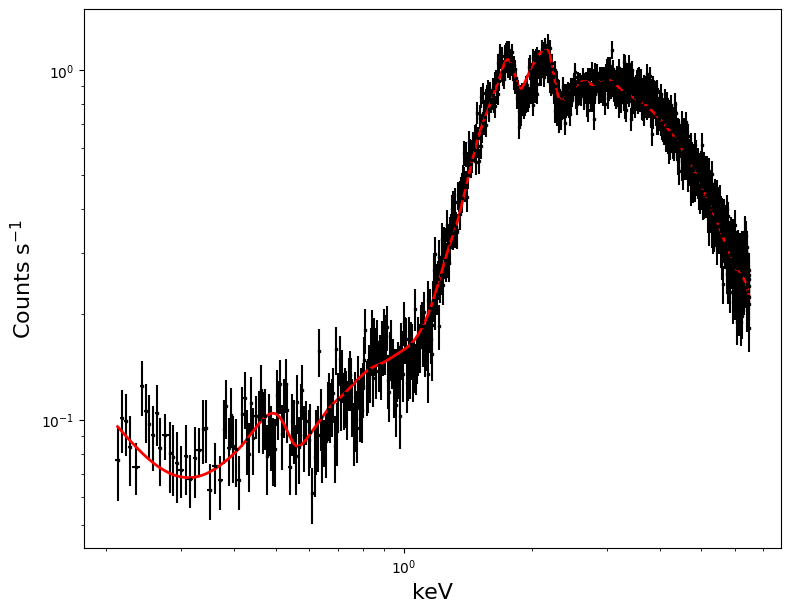

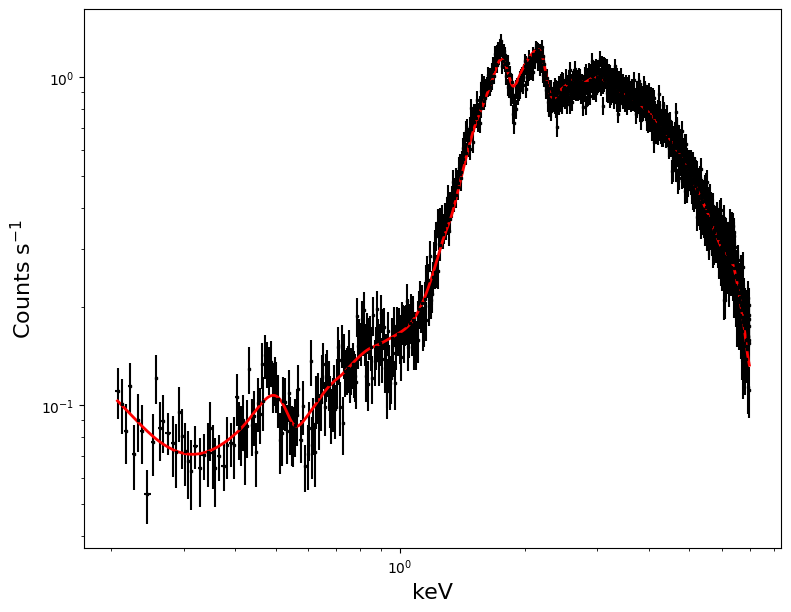

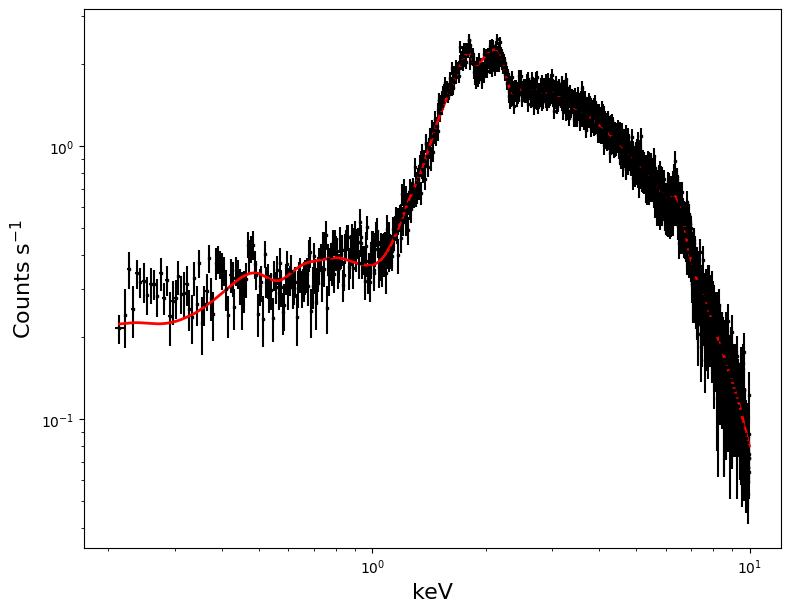

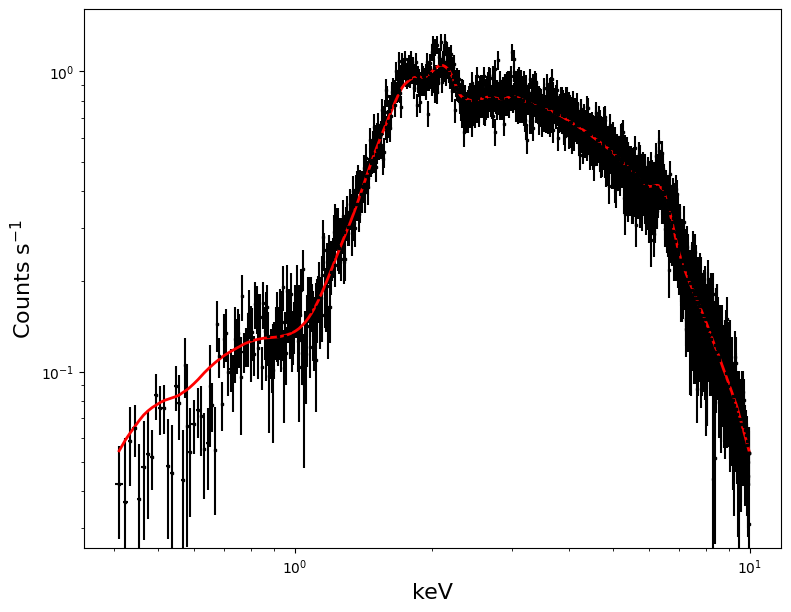

In [17]:
for ii in range(1,5):


    xspec.Plot.xAxis = "keV"


    xspec.Plot('data') 

    x  = xspec.Plot.x(plotGroup=ii)
    xe = xspec.Plot.xErr(plotGroup=ii)
    y  = xspec.Plot.y(plotGroup=ii)
    ye = xspec.Plot.yErr(plotGroup=ii)


    pm = xspec.Plot.model(plotGroup=ii)


    fig,ax = plt.subplots(1,figsize=(9,7))


    ax.errorbar(x,y,xerr=xe,yerr=ye,ls='',
                c='k',markersize=2,marker='s')

    ax.plot(x,pm,c='r',ls='-',lw=2)

    ax.set_xscale('log')
    ax.set_yscale('log')

    ax.set_xlabel('keV',fontsize=16)
    ax.set_ylabel(r'Counts s$^{-1}$',fontsize=16)
    
    fig.savefig(f'spectra_{ii}')

In [18]:
model_values=[]

for ie in range(1,33):
    
    value=mod1(ie).values[0]   
    model_values.append(value)



constant_values=[]

for io in range(2,5):
    value=xspec.AllModels(io).constant.factor.values[0]
    constant_values.append(value)
        

In [19]:
#  0013140101 conservative

# Fitting single spectra
os.chdir('/work2/sruedavargas/SAS-software/products/spectra_files')


mos1_sing_spec=[]
mos2_sing_spec=[]
pn0_sing_spec=[]
pn14_sing_spec=[]

for file in os.listdir():
    if file.startswith('sing_spec_0554170201') and file.endswith('_grp20.ds') and 'cons' in file:
        
        if 'MOS1' in file:
            mos1_sing_spec.append(file)
        elif 'MOS2' in file:
            mos2_sing_spec.append(file)
        elif 'PN' and 'pat0' in file:
            pn0_sing_spec.append(file)
        elif 'PN' and 'pat14' in file:
            pn14_sing_spec.append(file)
              

In [20]:
def sort_key(item):

    match = re.search(r'(\d+)_src', item)
    if match:
        return int(match.group(1))
    return 0


mos1_sing_spec_sorted = sorted(mos1_sing_spec, key=sort_key)
mos2_sing_spec_sorted = sorted(mos2_sing_spec, key=sort_key)
pn0_sing_spec_sorted = sorted(pn0_sing_spec, key=sort_key)
pn14_sing_spec_sorted = sorted(pn14_sing_spec, key=sort_key)


In [21]:
# Recovering averge spectra model values

def ret_model_values():
    
    for ele in zip(range(1,33), model_values):
        mod1(ele[0]).values=(ele[1],-1.)
        
    
    mod1.powerlaw.PhoIndex.frozen = False    
    mod1.powerlaw.PhoIndex.link = mod1.pexrav.PhoIndex

        
    for io in zip(range(2,5), constant_values):
        xspec.AllModels(io[0]).constant.factor.values=(io[1],-1)
         
    
#Getting spectra that do not contain data

def empty(spec_set):
    
    data_spec_files=[]
    
    for file in spec_set:
    
        with fits.open(file) as f:
            header_spec = f[1].header
            try:
                a = header_spec['EXPOSURE']
            except:
                print(f"No data in spectrum {file}")
            else:
                data_spec_files.append(file)
                        
    return(data_spec_files)
    

# Writing expression for data based on spectral set 


def data_expression(n_set, spectral_set):
    
    data_spec_expression=""
    n_list=[]
    exp_n_ar=[]
    
    for file in spectral_set:
        
        data_spec_expression+=f"{n_set}:{n_set} {file} "
        exp_n_ar.append((n_set, file))

        n_set+=1
                    
    return(data_spec_expression, exp_n_ar)


#Defining the energy range for each spectrum in the spectral set

def energies_spec(array_spec_set):
    
    for element in array_spec_set:
        
        data_group=element[0]
        spectrum_file=element[1]
        
        if 'MOS1' in spectrum_file:
            
            xspec.AllData(data_group).ignore(f"**-{low_mos1} {up_mos1}-**")
            
        elif 'MOS2' in spectrum_file:
            
            xspec.AllData(data_group).ignore(f"**-{low_mos2} {up_mos2}-**")
            
        elif 'PN' and 'pat0' in spectrum_file:

            xspec.AllData(data_group).ignore(f"**-{low_pn_0} {up_pn_0}-**")
        
        elif 'PN' and 'pat14' in spectrum_file:

            xspec.AllData(data_group).ignore(f"**-{low_pn_14} {up_pn_14}-**")
            



In [22]:
# xspec.Xset.chatter, xspec.Xset.logChatter = xchat

# xspec.AllData.clear()



# mos1_12_bin = 'sing_spec_0554170201_MOS1_cons_pat12_1_src_grp20.ds'
# mos2_12_bin = 'sing_spec_0554170201_MOS2_cons_pat12_1_src_grp20.ds'
# pn_0_bin = 'sing_spec_0554170201_PN_cons_pat0_1_src_grp20.ds'
# pn_14_bin = 'sing_spec_0554170201_PN_cons_pat14_1_src_grp20.ds'

# xspec.AllData(f"1:1 {mos1_12_bin} 2:2 {mos2_12_bin} 3:3 {pn_0_bin} 4:4 {pn_14_bin} ")


# xspec.AllData(1).ignore(f"**-{low_mos1} {up_mos1}-**")
# xspec.AllData(2).ignore(f"**-{low_mos2} {up_mos2}-**")
# xspec.AllData(3).ignore(f"**-{low_pn_0} {up_pn_0}-**")
# xspec.AllData(4).ignore(f"**-{low_pn_14} {up_pn_14}-**")


# ret_model_values()

# nh_par=mod1.zTBabs_7.nH
# phoindex=mod1.pexrav.PhoIndex

# values_nh_1=[]
# error_nh_1=[]

# values_pi_2=[]
# error_pi_2=[]
# values_nh_2=[]
# error_nh_2=[]

# mod1(15).frozen = False
# xspec.Fit.perform()
# values_nh_1.append(nh_par.values[0])
# xspec.Fit.error(f'2.706 15')
# error_nh_1.append(nh_par.error)

# mod1(17).frozen = False
# xspec.Fit.perform()
# values_nh_2.append(nh_par.values[0])
# values_pi_2.append(phoindex.values[0])

# xspec.Fit.error(f'2.706 15')
# xspec.Fit.error(f'2.706 17')

# error_nh_2.append(nh_par.error)
# error_pi_2.append(phoindex.error)


In [23]:
# print(values_nh_1)
# print(error_nh_1)

# print(values_pi_2)
# print(error_pi_2)
# print(values_nh_2)
# print(error_nh_2)

In [24]:
n_expression=1

nh_values_nh_free=[]
nh_error_nh_free=[]


chi2_nh_free=[]
dof_nh_free=[]

flux_02_10=[]
flux_02_2=[]
flux_2_10=[]


nh_values_nhgamma_free=[]
nh_error_nhgamma_free=[]

gamma_values_nhgamma_free=[]
gamma_error_nhgamma_free=[]


chi2_nhgamma_free=[]
dof_nhgamma_free=[]



for spset in zip(mos1_sing_spec_sorted,mos2_sing_spec_sorted,pn0_sing_spec_sorted,pn14_sing_spec_sorted):
    
    xspec.AllData.clear()
    
    use_files=empty(spset)
    expression_funct=data_expression(n_expression, use_files)
    
    data_exp_xspec=expression_funct[0]
    arr_set_en=expression_funct[1]

    xspec.AllData(f"{data_exp_xspec}")

    xspec.AllData.notice('all')
    xspec.AllData.ignore('bad')
    
    energies_spec(arr_set_en)
    
    ret_model_values()
    

    nh_par = mod1.zTBabs_7.nH
    phoindex_par = mod1.pexrav.PhoIndex
 
 #N_H and norm powerlaw free
    
    mod1(15).frozen = False
    mod1(24).frozen = False
    xspec.Fit.perform()
    nh_values_nh_free.append(nh_par.values[0])
    
    xspec.Fit.error('2.706 15')
    nh_error_nh_free.append(nh_par.error)
    
    chi2_nh_free_val=xspec.Fit.statistic
    chi2_nh_free.append(chi2_nh_free_val)
    
    dof_nh_free_val=xspec.Fit.dof
    dof_nh_free.append(dof_nh_free_val)
    
    xspec.AllModels.calcFlux('0.2 10.0 err 20 90')
    flux_02_10_val=xspec.AllData(3).flux
    flux_02_10.append(flux_02_10_val)
    
    xspec.AllModels.calcFlux('0.2 2.0 err 20 90')
    flux_02_2_val=xspec.AllData(3).flux
    flux_02_2.append(flux_02_2_val)
    
    #ADD
    
    xspec.AllModels.calcFlux('2.0 10.0 err 20 90')
    flux_2_10_val=xspec.AllData(3).flux
    flux_2_10.append(flux_2_10_val)
    
        
# N_H, gamma, and norm powerlaw free
    

    mod1(17).frozen = False
    xspec.Fit.perform()
    nh_values_nhgamma_free.append(nh_par.values[0])
    gamma_values_nhgamma_free.append(phoindex_par.values[0])
    
    chi2_nhgamma_free_val=xspec.Fit.statistic
    chi2_nhgamma_free.append(chi2_nhgamma_free_val)
    
    dof_nhgamma_free_val=xspec.Fit.dof
    dof_nhgamma_free.append(dof_nhgamma_free_val)

    xspec.Fit.error('2.706 15')
    nh_error_nhgamma_free.append(nh_par.error)
    
    xspec.Fit.error('2.706 17')
    gamma_error_nhgamma_free.append(phoindex_par.error)
    
    
               

Number of trials exceeded: continue fitting? Number of trials exceeded: continue fitting? 

In [25]:
xspec.Xset.chatter, xspec.Xset.logChatter = xchat

In [26]:
# Results N_H free 

print('N_H val', nh_values_nh_free)
print('N_H error',nh_error_nh_free)

print('chi2_nh_free', chi2_nh_free)
print('dof_nh_free', dof_nh_free)

print('flux_02_10', flux_02_10)
print('flux_02_2', flux_02_2)


# Results N_H and Gamma free 


print('N_H val (gamma free)', nh_values_nhgamma_free)
print('N_H error (gamma free)',nh_error_nhgamma_free)


print('Gamma val (gamma free)', gamma_values_nhgamma_free)
print('Gamma error (gamma free)', gamma_error_nhgamma_free)


print('chi2_nhgamma_free', chi2_nhgamma_free)
print('dof_nhgamma_free', dof_nhgamma_free)


N_H val [4.663743117122999, 4.646725380812386, 4.655257959400715, 4.617488562958063, 4.6659177690258]
N_H error [(4.61958282875144, 4.708577732731856, 'FFFFFFFFF'), (4.607218853510922, 4.686721052068732, 'FFFFFFFFF'), (4.613654764059105, 4.697454869390276, 'FFFFFFFFF'), (4.57360679953963, 4.661904111141956, 'FFFFFFFFF'), (4.61841744402079, 4.714264616841412, 'FFFFFFFFF')]
chi2_nh_free [3110.0290624443014, 3214.53906882476, 3441.5026995112603, 2953.7198574013064, 2839.24267748516]
dof_nh_free [3079, 3455, 3341, 3114, 2806]
flux_02_10 [(9.390117540162605e-11, 9.355432745013157e-11, 9.456415667479773e-11, 0.013385728969332527, 0.01333503221348836, 0.013468388903163233), (1.0552016549883928e-10, 1.0498260214453775e-10, 1.0601177073764633e-10, 0.01500716435565908, 0.01493926175202405, 0.015058169953476735), (9.830240620599251e-11, 9.796777389439833e-11, 9.87173695057661e-11, 0.014000792885819955, 0.013947883620424381, 0.014062158940575956), (9.198554700748691e-11, 9.1390821633322e-11, 9.249

In [27]:
chi2_dof_nh_free=np.divide(chi2_nh_free, dof_nh_free)
print(chi2_dof_nh_free)
chi2_dof_nhgamma_free=np.divide(chi2_nhgamma_free, dof_nhgamma_free)
print(chi2_dof_nhgamma_free)

[1.01007764 0.93040205 1.03008162 0.94852918 1.011847  ]
[1.00871622 0.93052397 1.0300745  0.94815203 1.00950358]


In [28]:
bin_gti='bin_gti_0554170201_PN_cons.fits'
time_values=[]


with fits.open(bin_gti) as f:
    data = f[1].data
    start=data.field(0)
    stop=data.field(1)
    
    for i in range(len(data)):
        start = data[i][0]
        stop = data[i][1]
        time_val = (stop + start)/2
        time_values.append(time_val)
        
        
points_plot=np.arange(1,len(nh_values_nh_free)+1,1)

In [29]:
def low_upper_error(values, errors):
    
    lower_errors = [values[i]-point[0]  for i, point in enumerate(errors)]
    upper_errors = [point[1] - values[i] for i, point in enumerate(errors)]
    
    return(lower_errors, upper_errors)


error_plot_nh_nh_free=low_upper_error(nh_values_nh_free, nh_error_nh_free)
error_plot_nh_nhgamma_free=low_upper_error(nh_values_nhgamma_free, nh_error_nhgamma_free)
error_plot_gamma_nhgamma_free=low_upper_error(gamma_values_nhgamma_free, gamma_error_nhgamma_free)

def flux(result_flux):
    
    value=[]
    lower=[]
    upper=[]
    
    for element in result_flux:
        
    
        lower_errors = element[0]-element[1]
        upper_errors = element[2] - element[0]
        
        lower.append(lower_errors)
        upper.append(upper_errors)
        value.append(element[0])
        
    
    return(value, lower, upper)

plot_flux_02_10=flux(flux_02_10)
plot_flux_02_2=flux(flux_02_2)

#ADD
plot_flux_2_10=flux(flux_2_10)

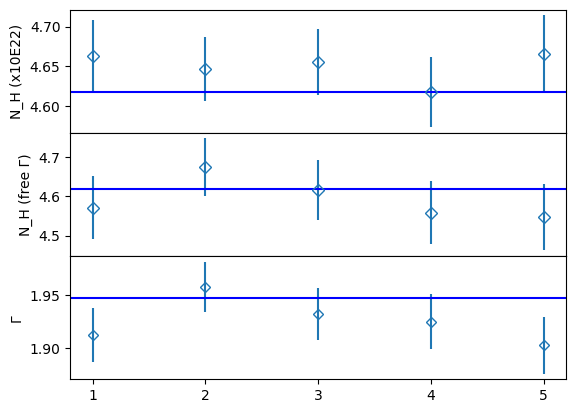

In [30]:
fig, axes = plt.subplots(3, 1, sharex=True)
fig.subplots_adjust(hspace=0)
# plt.locator_params(nbins=9)

axes[0].errorbar(points_plot,nh_values_nh_free , yerr=[error_plot_nh_nh_free[0], error_plot_nh_nh_free[1]], fmt='D', capsize=0, mfc='none', label='N_H free')
axes[0].axhline(y = av_nh_val, color = 'b', linestyle = '-')
axes[0].set_ylabel('N_H (x10E22)')


axes[1].errorbar(points_plot,nh_values_nhgamma_free, yerr=[error_plot_nh_nhgamma_free[0], error_plot_nh_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', label='N_H and \u0393 free')
axes[1].axhline(y = av_nh_val, color = 'b', linestyle = '-')
axes[1].set_ylabel('N_H (free \u0393)')


axes[2].errorbar(points_plot,gamma_values_nhgamma_free, yerr=[error_plot_gamma_nhgamma_free[0], error_plot_gamma_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', markersize=5, label='N_H and \u0393 free')
axes[2].axhline(y = av_gamma_val, color = 'b', linestyle = '-')
axes[2].set_ylabel('\u0393')

plt.xticks(points_plot)
plt.savefig('parameters-1')
plt.show()


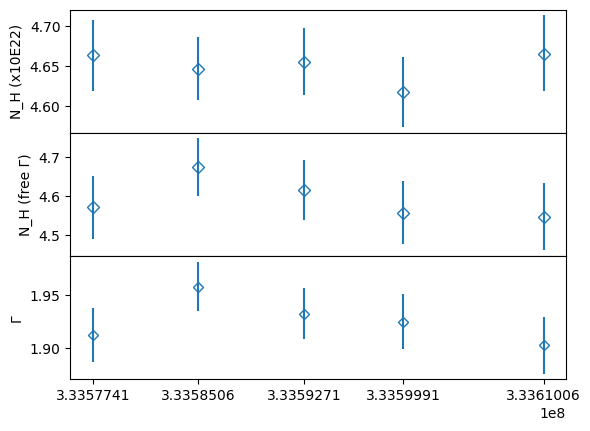

In [31]:
fig, axes = plt.subplots(3, 1, sharex=True)
fig.subplots_adjust(hspace=0)
# plt.locator_params(nbins=9)

axes[0].errorbar(time_values,nh_values_nh_free , yerr=[error_plot_nh_nh_free[0], error_plot_nh_nh_free[1]], fmt='D', capsize=0, mfc='none', label='N_H free')
axes[0].set_ylabel('N_H (x10E22)')


axes[1].errorbar(time_values,nh_values_nhgamma_free, yerr=[error_plot_nh_nhgamma_free[0], error_plot_nh_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', label='N_H and \u0393 free')
axes[1].set_ylabel('N_H (free \u0393)')


axes[2].errorbar(time_values,gamma_values_nhgamma_free, yerr=[error_plot_gamma_nhgamma_free[0], error_plot_gamma_nhgamma_free[1]], fmt='D', capsize=0, mfc='none', markersize=5, label='N_H and \u0393 free')
axes[2].set_ylabel('\u0393')



plt.xticks(time_values)
plt.show()

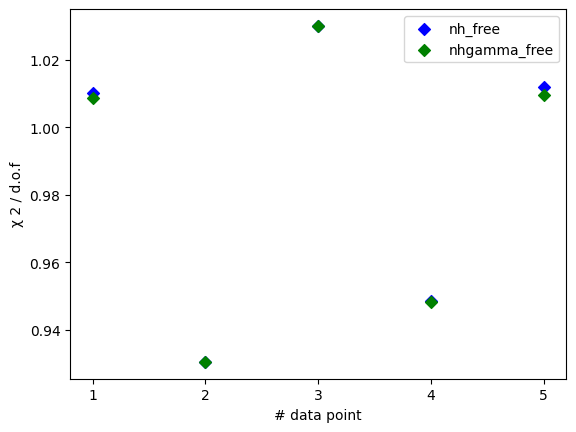

In [32]:
plt.scatter(points_plot, chi2_dof_nh_free, color='b', marker='D', label='nh_free')
plt.scatter(points_plot, chi2_dof_nhgamma_free, color='g', marker='D', label='nhgamma_free')
plt.xlabel("# data point")
plt.ylabel("\u03C7 2 / d.o.f")

  
plt.legend()
plt.xticks(points_plot)

plt.savefig('chi2-1') 
plt.show()

In [33]:
hr1 = np.subtract(plot_flux_2_10[0],plot_flux_02_2[0])
hr2 = np.add(plot_flux_2_10[0],plot_flux_02_2[0])
HR = np.divide(hr1,hr2)


In [41]:
def hr_unc(hard,soft,n_lim):
    exp1=np.square(hard[n_lim])*np.square(soft[0])
    exp2=np.square(soft[n_lim])*np.square(hard[0])
    exp3=np.divide(4,np.power(np.add(hard[0],soft[0]),4))
    exp4=np.multiply(exp3,np.add(exp1,exp2))
    exp5=np.sqrt(exp4)
    return(exp5)


low_hr_unc=hr_unc(plot_flux_2_10,plot_flux_02_2,1)
up_hr_unc=hr_unc(plot_flux_2_10,plot_flux_02_2,2)

hr_uncertainities=[low_hr_unc,up_hr_unc]


[0.00118471 0.00048776 0.00080443 0.00108504 0.00121152]
[0.00085432 0.00077224 0.00100938 0.00122153 0.00104594]
[0.00118471 0.00048776 0.00080443 0.00108504 0.00121152]


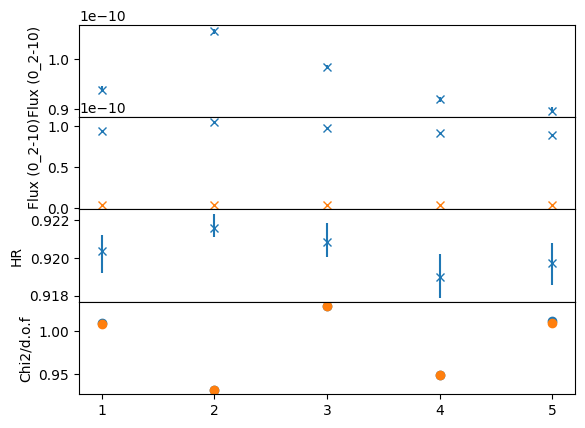

In [42]:
fig, axes = plt.subplots(4, 1, sharex=True)
fig.subplots_adjust(hspace=0)
# plt.locator_params(nbins=9)


axes[0].errorbar(points_plot,plot_flux_02_10[0] , yerr=[plot_flux_02_10[1], plot_flux_02_10[2]], fmt='x', capsize=0, mfc='none', label='N_H free')
axes[0].set_ylabel('Flux (0_2-10)')


axes[1].errorbar(points_plot,plot_flux_02_10[0] , yerr=[plot_flux_02_10[1], plot_flux_02_10[2]], fmt='x', capsize=0, mfc='none', label='N_H free')
axes[1].errorbar(points_plot,plot_flux_02_2[0] , yerr=[plot_flux_02_2[1], plot_flux_02_2[2]], fmt='x', capsize=0, mfc='none', label='N_H free')
axes[1].set_ylabel('Flux (0_2-10)')

axes[2].errorbar(points_plot,HR, yerr=[hr_uncertainities[0], hr_uncertainities[1]], fmt='x', capsize=0, mfc='none')
axes[2].set_ylabel('HR')

axes[3].scatter(points_plot, chi2_dof_nh_free)
axes[3].scatter(points_plot, chi2_dof_nhgamma_free)
axes[3].set_ylabel('Chi2/d.o.f')


plt.xticks(points_plot)
plt.show()

In [ ]:
results={"av_nh_val": av_nh_val, "av_gamma_val": av_gamma_val, "points_plot": points_plot, 
         "nh_values_nh_free":nh_values_nh_free, "error_plot_nh_nh_free":error_plot_nh_nh_free, 
        "nh_values_nhgamma_free":nh_values_nhgamma_free, "error_plot_nh_nhgamma_free": error_plot_nh_nhgamma_free,
        "gamma_values_nhgamma_free":error_plot_gamma_nhgamma_free, "time_values":time_values, 
        "chi2_dof_nh_free":chi2_dof_nh_free, "chi2_dof_nhgamma_free":chi2_dof_nhgamma_free,
        "plot_flux_02_10":plot_flux_02_10, "plot_flux_02_2":plot_flux_02_2, "HR":HR, "hr_uncertainities":hr_uncertainities}





In [ ]:
column_names = ["av_nh_val", "av_gamma_val", "points_plot", 
             "nh_values_nh_free", "error_plot_nh_nh_free", 
            "nh_values_nhgamma_free", "error_plot_nh_nhgamma_free",
            "gamma_values_nhgamma_free", "time_values", 
            "chi2_dof_nh_free", "chi2_dof_nhgamma_free",
            "plot_flux_02_10", "plot_flux_02_2", "HR", "hr_uncertainities"]

results_object = pd.DataFrame(columns=column_names)

In [ ]:
results_df = pd.DataFrame([results], index=[f"this_obs"])
    
results_object = pd.concat([results_object, results_df])